# 02 – Data understanding of the medical datasets

## Purpose
Before comparing ensemble methods, each dataset is audited for the properties that condition a fair comparison:

1. size, feature types and **class balance**;
2. **missing values**;
3. **duplicate rows**, and the risk that identical records fall on both sides of a train/test split;
4. features that **predict the target almost alone** (possible leakage or a trivially separable problem);
5. the score reached by **default models**, compared with the majority-class rule, to estimate how much room exists to separate methods.

In every binary dataset the positive class (`y = 1`) is the **disease** class, so that precision, recall and F1 refer to the diseased patients.
D15 (HAM10000 metadata) has seven diagnostic classes and is audited in its own section (section 13) with macro-averaged metrics.

## Scope of this run
The datasets found in `data/raw/` at execution time are analysed; the list is printed in section 1.
Datasets that cannot be loaded are reported with their error message and are not covered by the interpretations.
All random operations use the seed defined in `configs/config.yaml`.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from ensemble_disease.config import load_config, set_seed
from ensemble_disease.data import REGISTRY
from ensemble_disease import eda

cfg = load_config(); SEED = cfg["seed"]; set_seed(SEED)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
eda.RESULTS.mkdir(exist_ok=True)
print("seed =", SEED)

seed = 42


## 1. Loading the datasets
Each binary dataset is loaded as a pair `(X, y)`. Text cells are stripped, `?` and empty strings become missing values, and numeric columns stored as text are converted back to numbers.
D15 is multiclass and is loaded separately in section 13.

In [2]:
data, errors = eda.load_all()
data.pop("D15", None); errors.pop("D15", None)      # multiclass: handled in section 13
print(f"Loaded {len(data)} binary datasets:", list(data))
if errors:
    print("\nDatasets not loaded (source file not found or unreadable):")
    for k, v in errors.items():
        print(f"  - {k}: {v[:110]}")

Loaded 14 binary datasets: ['D2_heart_cleveland', 'D5_liver_disorders', 'D6_ilpd', 'D8_early_diabetes', 'D11_debrecen', 'D12_ckd', 'D16_dermatology', 'D4_heart_failure', 'D10_diabetes_2019', 'D1_heart_comprehensive', 'D3_heart_disease', 'D9_diabetes_pima', 'D13_ckd_kaggle', 'D14_kidney_stone']

Datasets not loaded (source file not found or unreadable):
  - D7_covid_liver_cancer: UnicodeDecodeError: 'utf-8' codec can't decode byte 0x97 in position 14: invalid start byte
  - D15_ham10000: skipped: multiclass dataset (binary pipeline only)


## 2. Definition of the target (`y = 1`)

In [3]:
pd.DataFrame({k: dict(positive_class_rule=v["note"]) for k, v in REGISTRY.items()}).T

,positive_class_rule
D2_heart_cleveland,"num 0 = healthy, 1..4 = disease -> disease = num > 0"
D5_liver_disorders,"VERIFY: label = 'selector' (1: 145, 2: 200), 'drinks' kept as a feature. Selector is a train/test split flag in UCI, not a clean diagnosis"
D6_ilpd,"Selector 1 = liver patient (416), 2 = non-patient (167)"
D8_early_diabetes,class Positive / Negative
D11_debrecen,Class 1 = signs of diabetic retinopathy
D12_ckd,class ckd / notckd (raw file has stray tabs/spaces)
D16_dermatology,VERIFY: 6 classes. Binarised as psoriasis (class 1) vs rest; decide multiclass vs binary
D4_heart_failure,Kaggle: heart_failure_clinical_records_dataset.csv ; DEATH_EVENT 1 = died
D10_diabetes_2019,VERIFY: Kaggle diabetes 2019 file; column name and yes/no spelling
D1_heart_comprehensive,"VERIFY: Kaggle 'Heart Disease Dataset (Comprehensive)', 1190 rows; target 1 = heart disease"


**Interpretation.**

## 3. Summary of the datasets

In [4]:
summary = eda.summary_table(data)
summary.to_csv(eda.RESULTS / "eda_summary.csv")
display(summary)

,n,n_features,n_numeric,n_categorical,pos,neg,pos_pct,imbalance_ratio,missing_cells,missing_pct,rows_with_missing,duplicate_rows,duplicate_pct,constant_cols
dataset,,,,,,,,,,,,,,
D2_heart_cleveland,303,13,13,0,139,164,45.9,1.18,6,0.15,6,0,0.00,0
D5_liver_disorders,345,6,6,0,145,200,42.0,1.38,0,0.00,0,4,1.16,0
D6_ilpd,583,10,9,1,416,167,71.4,2.49,4,0.07,4,13,2.23,0
D8_early_diabetes,520,16,1,15,320,200,61.5,1.60,0,0.00,0,269,51.73,0
D11_debrecen,1151,19,19,0,611,540,53.1,1.13,0,0.00,0,5,0.43,0
D12_ckd,400,24,14,10,250,150,62.5,1.67,1012,10.54,242,0,0.00,0
D16_dermatology,366,34,34,0,112,254,30.6,2.27,8,0.06,8,0,0.00,0
D4_heart_failure,299,12,12,0,96,203,32.1,2.11,0,0.00,0,0,0.00,0
D10_diabetes_2019,951,17,4,13,266,685,28.0,2.58,46,0.28,46,643,67.61,0


Definitions: `imbalance_ratio` = majority / minority class size; `duplicate_rows` = rows whose features are an exact copy of an earlier row; `rows_with_missing` = rows with at least one missing cell.

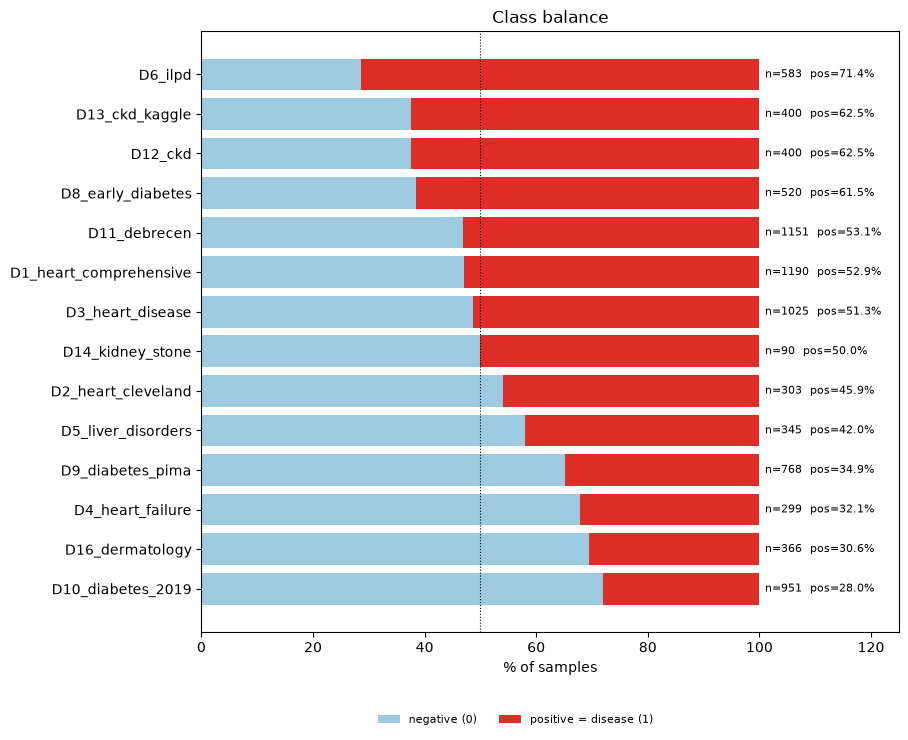

In [5]:
eda.plot_class_balance(summary); plt.show()

**Interpretation.**

## 4. Missing values

,n,missing_cells,missing_pct,rows_with_missing
dataset,,,,
D2_heart_cleveland,303,6,0.15,6
D5_liver_disorders,345,0,0.00,0
D6_ilpd,583,4,0.07,4
D8_early_diabetes,520,0,0.00,0
D11_debrecen,1151,0,0.00,0
D12_ckd,400,1012,10.54,242
D16_dermatology,366,8,0.06,8
D4_heart_failure,299,0,0.00,0
D10_diabetes_2019,951,46,0.28,46


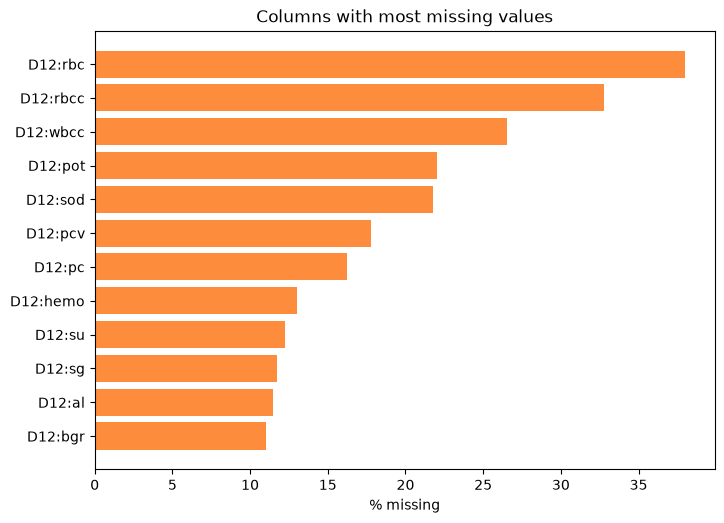

In [6]:
display(summary[["n", "missing_cells", "missing_pct", "rows_with_missing"]])
eda.plot_missing(data); plt.show()

**Interpretation.**

## 5. Comparison with Table 2 of the reference article
The sample sizes, attribute counts and class counts reported in Table 2 of the article (stored in the dataset registry) are compared with those of the versions used here.
`diff = ours − article`. In the article, the column *Positive/Negative* lists the positive count first.

In [7]:
ARTICLE = {k: REGISTRY[k]["article"] for k in data}
cmp_ = eda.compare_with_article(summary, ARTICLE)
cmp_.to_csv(eda.RESULTS / "eda_article_comparison.csv", index=False)
display(cmp_.pivot(index="dataset", columns="quantity", values="diff").fillna("").rename(columns=lambda c: f"diff_{c}"))
display(cmp_)

quantity,diff_n,diff_n_features,diff_neg,diff_pos
dataset,,,,
D10_diabetes_2019,-1.0,0.0,0.0,-1.0
D11_debrecen,0.0,1.0,0.0,0.0
D12_ckd,0.0,-1.0,-100.0,100.0
D13_ckd_kaggle,0.0,0.0,0.0,0.0
D14_kidney_stone,0.0,0.0,0.0,0.0
D16_dermatology,0.0,-1.0,,
D1_heart_comprehensive,0.0,0.0,0.0,0.0
D2_heart_cleveland,0.0,0.0,26.0,-26.0
D3_heart_disease,0.0,0.0,0.0,0.0


,dataset,quantity,ours,article,diff
0,D2_heart_cleveland,n,303,303,0
1,D2_heart_cleveland,n_features,13,13,0
2,D2_heart_cleveland,pos,139,165,-26
3,D2_heart_cleveland,neg,164,138,26
4,D5_liver_disorders,n,345,345,0
5,D5_liver_disorders,n_features,6,7,-1
6,D5_liver_disorders,pos,145,200,-55
7,D5_liver_disorders,neg,200,145,55
8,D6_ilpd,n,583,583,0
9,D6_ilpd,n_features,10,10,0


**Interpretation.**

## 6. Column types and categorical values
The distinct values of every text column are listed to detect typing errors, case or whitespace variants and unexpected codes.

In [8]:
for name, (X, y) in data.items():
    print(f"\n===== {name}   shape={X.shape}")
    rep = eda.categorical_report(X)
    if len(rep):
        display(rep)
    else:
        print("   (all features numeric)")


===== D2_heart_cleveland   shape=(303, 13)
   (all features numeric)

===== D5_liver_disorders   shape=(345, 6)
   (all features numeric)

===== D6_ilpd   shape=(583, 10)


,column,n_unique,values
0,Gender,2,"{'Male': 441, 'Female': 142}"



===== D8_early_diabetes   shape=(520, 16)


,column,n_unique,values
0,gender,2,"{'Male': 328, 'Female': 192}"
1,polyuria,2,"{'No': 262, 'Yes': 258}"
2,polydipsia,2,"{'No': 287, 'Yes': 233}"
3,sudden_weight_loss,2,"{'No': 303, 'Yes': 217}"
4,weakness,2,"{'Yes': 305, 'No': 215}"
5,polyphagia,2,"{'No': 283, 'Yes': 237}"
6,genital_thrush,2,"{'No': 404, 'Yes': 116}"
7,visual_blurring,2,"{'No': 287, 'Yes': 233}"
8,itching,2,"{'No': 267, 'Yes': 253}"
9,irritability,2,"{'No': 394, 'Yes': 126}"



===== D11_debrecen   shape=(1151, 19)
   (all features numeric)

===== D12_ckd   shape=(400, 24)


,column,n_unique,values
0,rbc,2,"{'normal': 201, 'abnormal': 47}"
1,pc,2,"{'normal': 259, 'abnormal': 76}"
2,pcc,2,"{'notpresent': 354, 'present': 42}"
3,ba,2,"{'notpresent': 374, 'present': 22}"
4,htn,2,"{'no': 251, 'yes': 147}"
5,dm,2,"{'no': 261, 'yes': 137}"
6,cad,2,"{'no': 364, 'yes': 34}"
7,appet,2,"{'good': 317, 'poor': 82}"
8,pe,2,"{'no': 323, 'yes': 76}"
9,ane,2,"{'no': 339, 'yes': 60}"



===== D16_dermatology   shape=(366, 34)
   (all features numeric)

===== D4_heart_failure   shape=(299, 12)
   (all features numeric)

===== D10_diabetes_2019   shape=(951, 17)


,column,n_unique,values
0,Age,4,"{'less than 40': 487, '40-49': 164, '50-59': 156, '60 or older': 144}"
1,Gender,2,"{'Male': 580, 'Female': 371}"
2,Family_Diabetes,2,"{'no': 498, 'yes': 453}"
3,highBP,2,"{'no': 723, 'yes': 228}"
4,PhysicallyActive,4,"{'less than half an hr': 336, 'more than half an hr': 271, 'one hr or more': 212, 'none': 132}"
5,Smoking,2,"{'no': 843, 'yes': 108}"
6,Alcohol,2,"{'no': 759, 'yes': 192}"
7,RegularMedicine,3,"{'no': 614, 'yes': 336, 'o': 1}"
8,JunkFood,4,"{'occasionally': 671, 'often': 184, 'very often': 52, 'always': 44}"
9,Stress,4,"{'sometimes': 564, 'very often': 164, 'not at all': 135, 'always': 88}"



===== D1_heart_comprehensive   shape=(1190, 11)
   (all features numeric)

===== D3_heart_disease   shape=(1025, 13)
   (all features numeric)

===== D9_diabetes_pima   shape=(768, 8)
   (all features numeric)

===== D13_ckd_kaggle   shape=(400, 13)
   (all features numeric)

===== D14_kidney_stone   shape=(90, 7)
   (all features numeric)


**Interpretation.**

## 7. Leakage check A – identical records in the training and test sets

In [9]:
leak = pd.DataFrame({k: eda.duplicate_leakage(X, y, seed=SEED) for k, (X, y) in data.items()}).T
leak.to_csv(eda.RESULTS / "eda_duplicate_leakage.csv")
display(leak)

,test_rows_with_train_copy_pct,dup_groups,dup_groups_conflicting_labels
D2_heart_cleveland,0.00,0.0,0.0
D5_liver_disorders,1.71,4.0,0.0
D6_ilpd,3.56,13.0,0.0
D8_early_diabetes,68.88,107.0,0.0
D11_debrecen,0.68,5.0,0.0
D12_ckd,0.00,0.0,0.0
D16_dermatology,0.00,0.0,0.0
D4_heart_failure,0.00,0.0,0.0
D10_diabetes_2019,90.96,238.0,19.0
D1_heart_comprehensive,36.40,272.0,0.0


`test_rows_with_train_copy_pct` is the percentage of test rows that have an identical copy in the training set, for a random stratified 80/20 split averaged over 50 repetitions.
`dup_groups_conflicting_labels` counts groups of identical records that carry different labels (irreducible label noise).

**Interpretation.**

## 8. Leakage check B – predictive power of a single feature

In [10]:
auc_tables = {k: eda.single_feature_auc(X, y) for k, (X, y) in data.items()}
top = pd.DataFrame({k: dict(zip(["top1", "top2", "top3"],
        [f"{r.feature} ({r.strength})" for r in t.head(3).itertuples()])) for k, t in auc_tables.items()}).T
display(top)

,top1,top2,top3
D2_heart_cleveland,thal (0.764),cp (0.754),ca (0.749)
D5_liver_disorders,gammagt (0.628),sgot (0.584),sgpt (0.579)
D6_ilpd,Sgot (0.697),TB (0.693),Sgpt (0.686)
D8_early_diabetes,polyuria (0.842),polydipsia (0.832),gender (0.723)
D11_debrecen,ma1 (0.663),ma2 (0.648),ma3 (0.632)
D12_ckd,hemo (0.967),pcv (0.952),sc (0.922)
D16_dermatology,clubbing of the rete ridges (0.984),thinning of the suprapapillary epidermis (0.981),elongation of the rete ridges (0.916)
D4_heart_failure,time (0.836),serum_creatinine (0.728),ejection_fraction (0.676)
D10_diabetes_2019,RegularMedicine (0.817),BPLevel (0.706),highBP (0.678)
D1_heart_comprehensive,ST slope (0.778),chest pain type (0.766),max heart rate (0.742)


`strength = max(AUC, 1 − AUC)` is the ROC-AUC obtained when a single feature is used alone as a score (0.5 = no information, 1.0 = perfect separation).
For categorical variables the AUC is computed on the category codes; for binary variables the symmetric definition of `strength` makes the coding order irrelevant.

**Interpretation.**

## 9. Default models compared with the majority-class rule

In [11]:
base = pd.DataFrame({k: eda.quick_baselines(X, y, seed=SEED) for k, (X, y) in data.items()}).T
base.to_csv(eda.RESULTS / "eda_baselines.csv")
display(base)

,majority_acc,majority_f1,majority_acc_std,tree_acc,tree_f1,tree_acc_std,forest_acc,forest_f1,forest_acc_std
D2_heart_cleveland,0.541,0.000,0.005,0.765,0.751,0.047,0.835,0.812,0.045
D5_liver_disorders,0.580,0.000,0.000,0.612,0.520,0.038,0.722,0.630,0.066
D6_ilpd,0.714,0.833,0.004,0.631,0.732,0.026,0.710,0.809,0.036
D8_early_diabetes,0.615,0.762,0.000,0.965,0.972,0.014,0.979,0.983,0.013
D11_debrecen,0.531,0.694,0.001,0.620,0.643,0.020,0.678,0.688,0.028
D12_ckd,0.625,0.769,0.000,0.975,0.980,0.018,0.992,0.994,0.006
D16_dermatology,0.694,0.000,0.006,0.995,0.991,0.007,1.000,1.000,0.000
D4_heart_failure,0.679,0.000,0.006,0.752,0.604,0.048,0.846,0.741,0.042
D10_diabetes_2019,0.720,0.000,0.002,0.961,0.927,0.009,0.965,0.935,0.010
D1_heart_comprehensive,0.529,0.692,0.002,0.882,0.887,0.007,0.932,0.936,0.014


Protocol: 5-fold stratified cross-validation (one repetition) of a majority-class rule, a default decision tree and a default random forest (200 trees). Median imputation and one-hot encoding are inside the pipeline.
This is a diagnostic of the data, not the final experimental protocol. `_acc` = accuracy, `_f1` = F1 of the positive class, `_std` = standard deviation over the folds.

**Interpretation.**

## 10. Correlations between numeric features

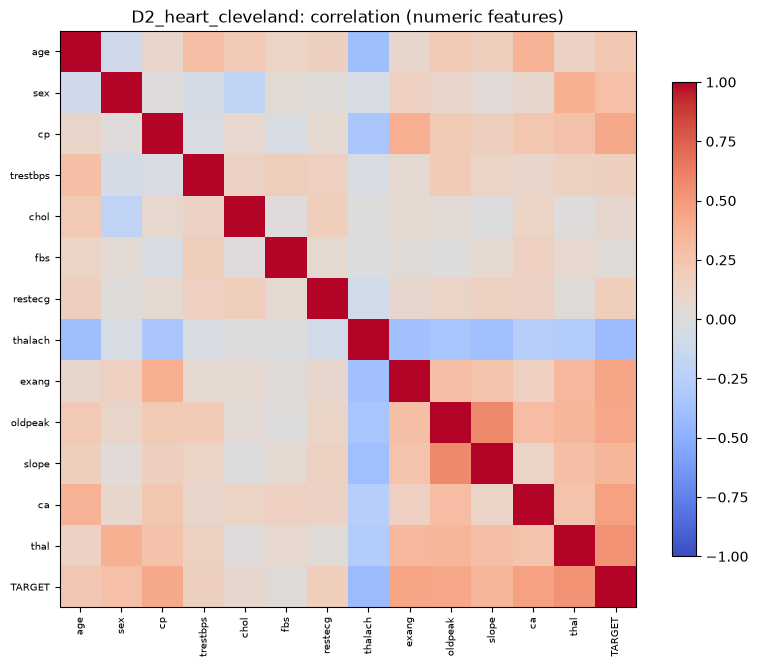

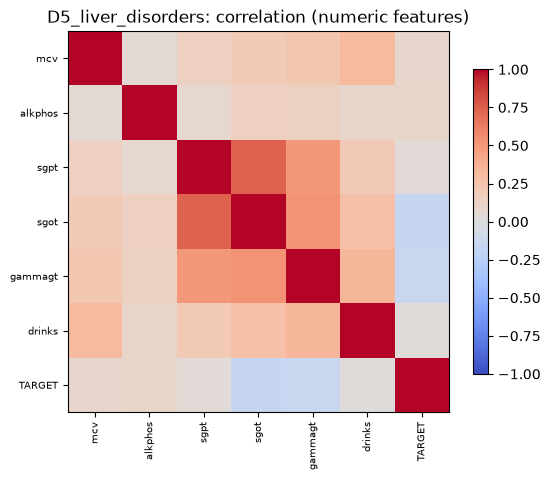

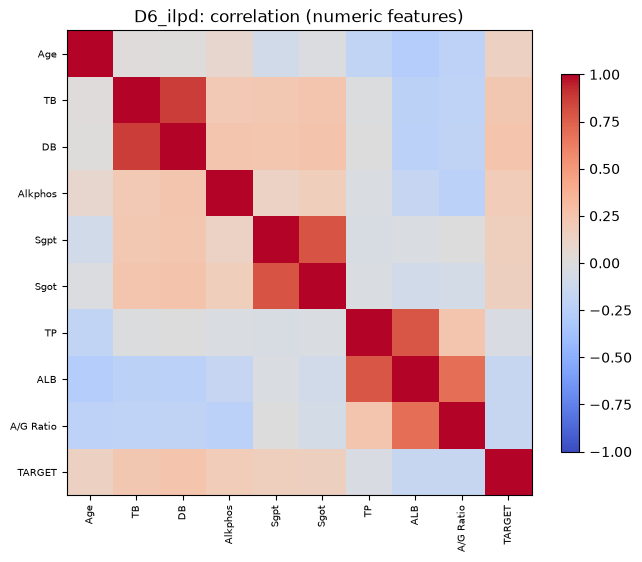

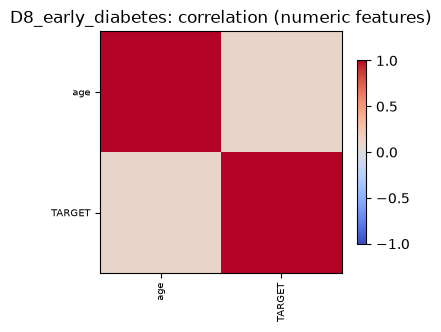

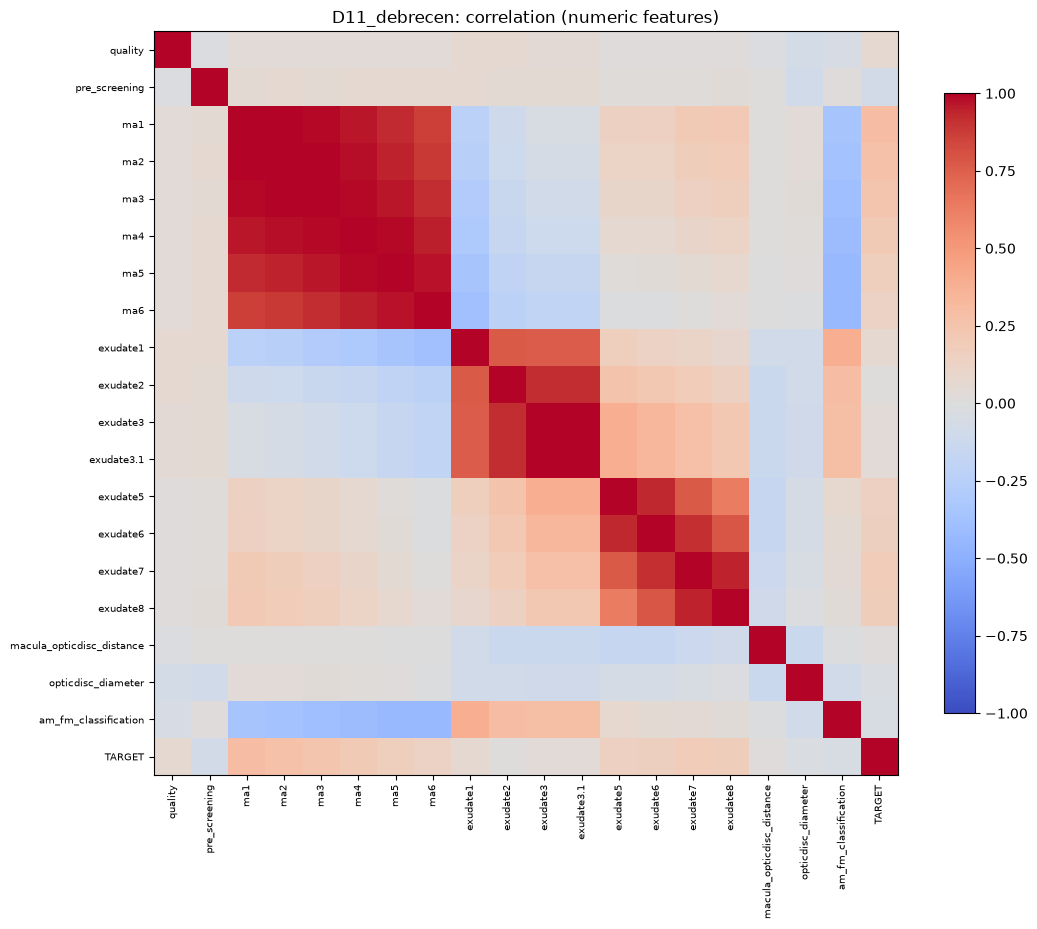

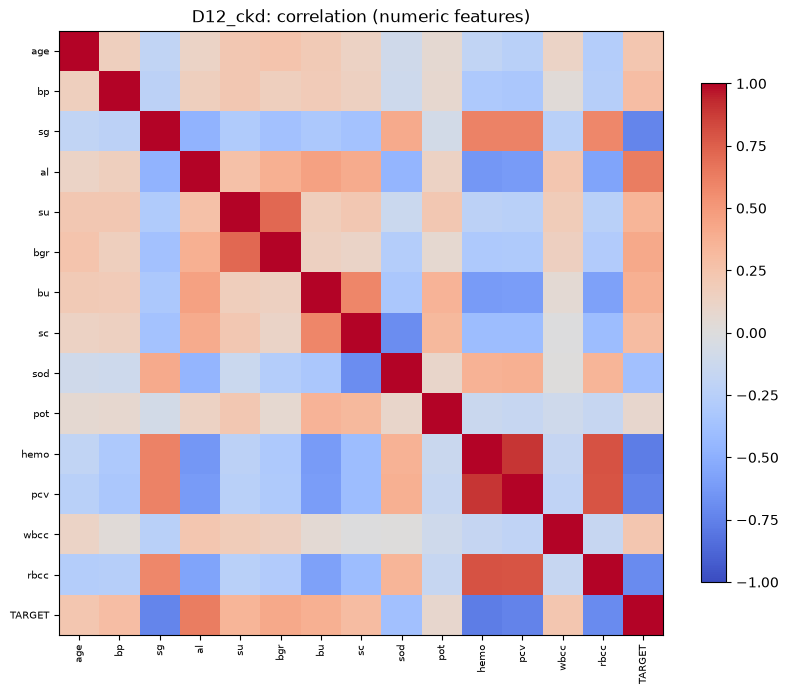

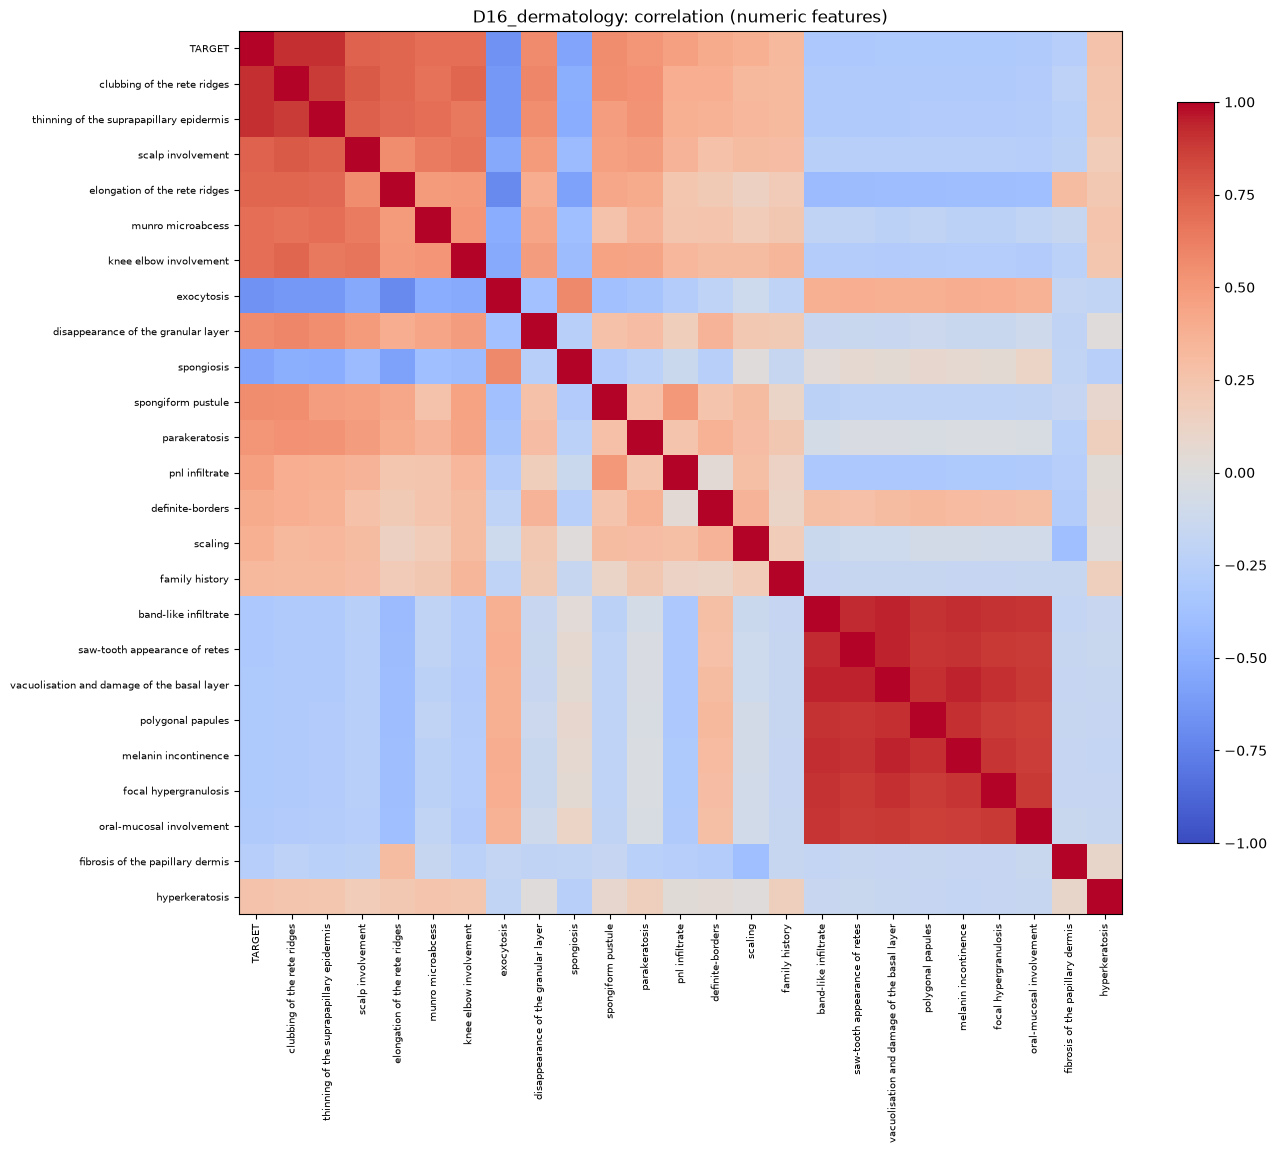

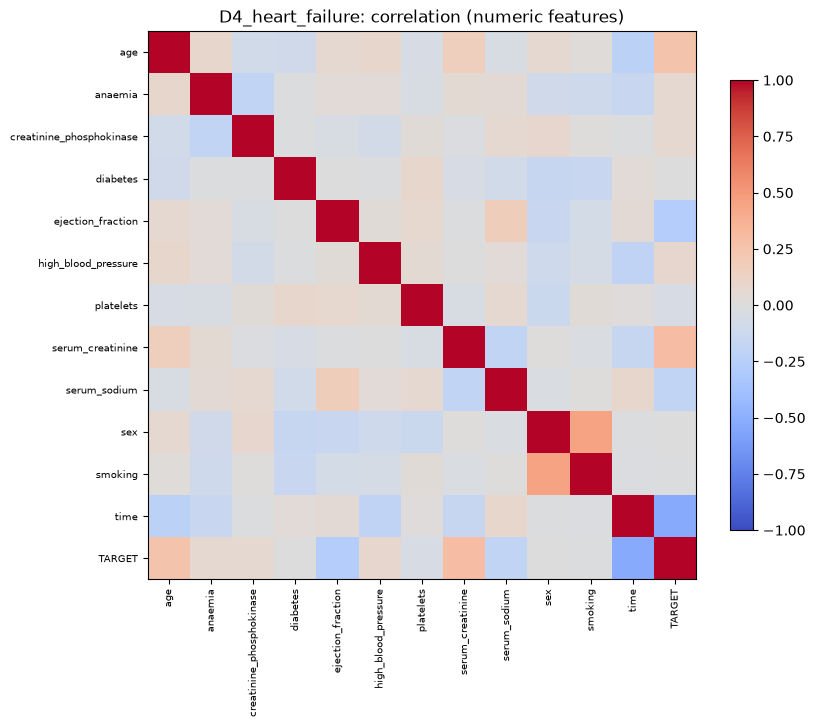

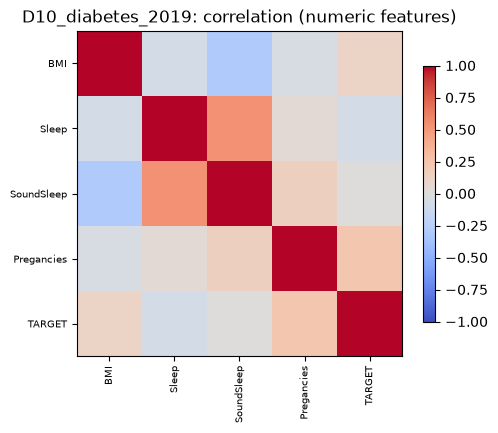

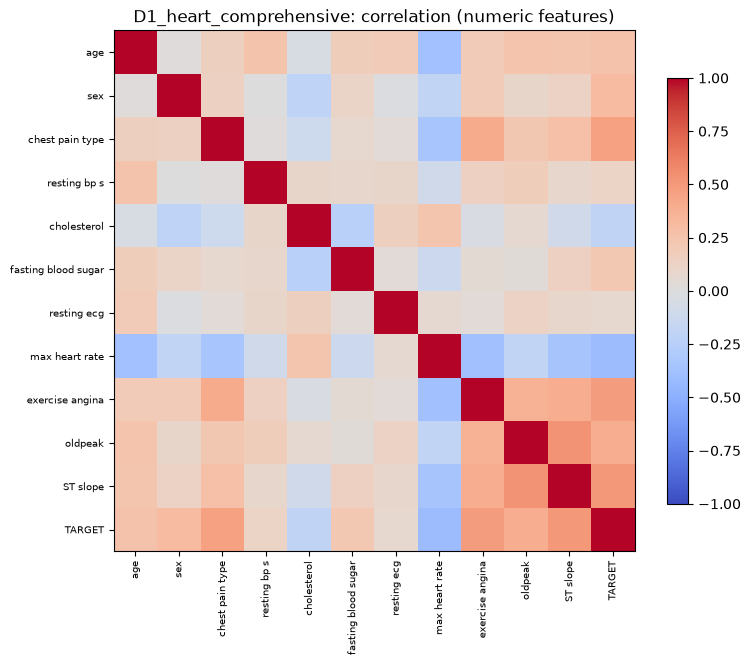

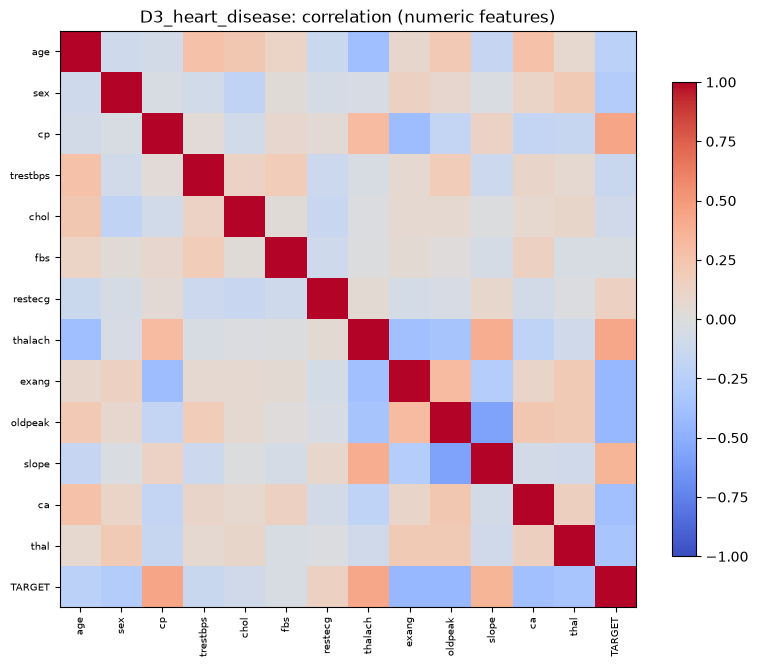

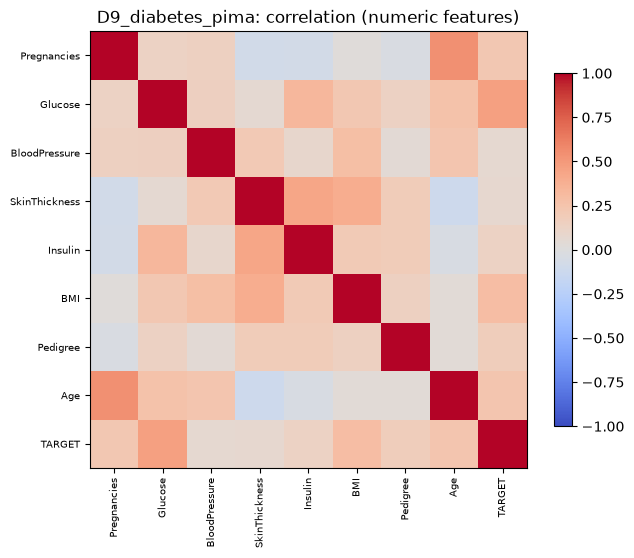

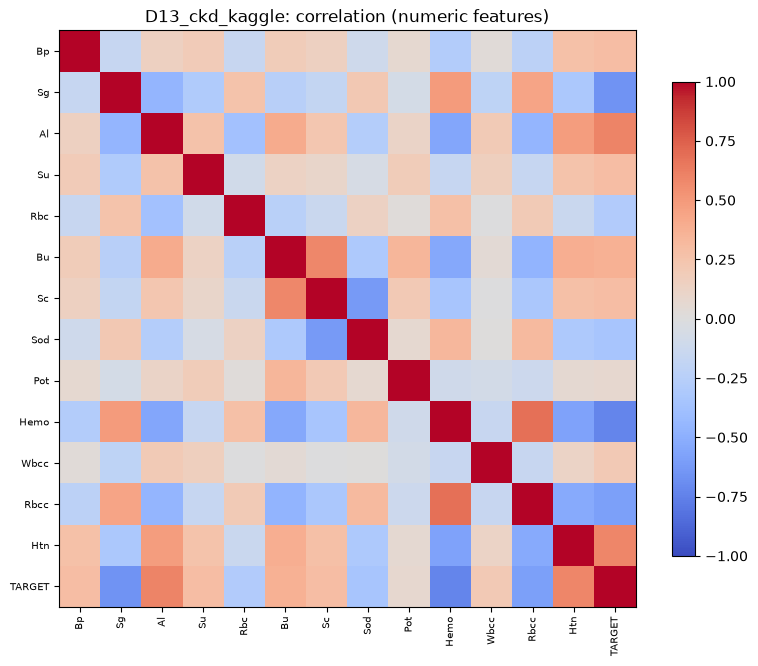

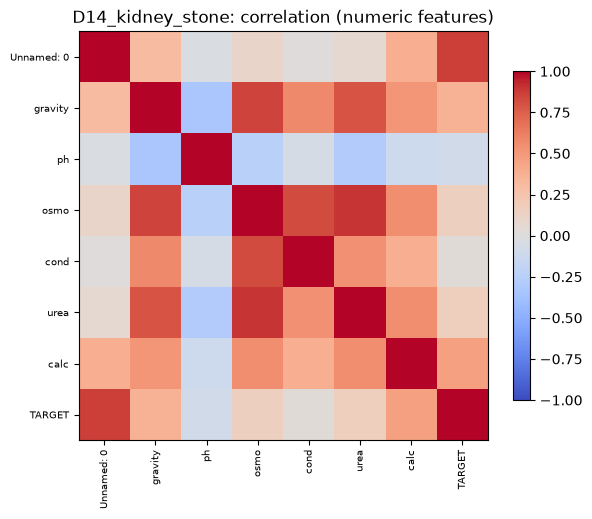

In [12]:
for name, (X, y) in data.items():
    eda.plot_corr(X, y, name); plt.show()

**Interpretation.**

## 11. Summary of data-quality flags

In [13]:
warn = []
for k in data:
    s = summary.astype(object).loc[k]
    if s.imbalance_ratio >= 3: warn.append((k, f"imbalanced (ratio {s.imbalance_ratio}) -> use F1/AUPRC, stratified splits"))
    if s.missing_pct > 0:      warn.append((k, f"{s.missing_cells} missing cells -> imputation must be inside CV folds"))
    if s.duplicate_rows > 0:   warn.append((k, f"{s.duplicate_rows} duplicate rows ({s.duplicate_pct}%)"))
    if leak.loc[k, "test_rows_with_train_copy_pct"] >= 1: warn.append((k, f"{leak.loc[k,'test_rows_with_train_copy_pct']}% of test rows have a train copy"))
    if s.constant_cols > 0:    warn.append((k, f"{s.constant_cols} constant column(s)"))
    if s.n < 400:              warn.append((k, f"small (n={s.n}) -> high variance, use repeated CV"))
    if auc_tables[k].strength.iloc[0] >= 0.90: warn.append((k, f"feature '{auc_tables[k].feature.iloc[0]}' alone gives strength {auc_tables[k].strength.iloc[0]}"))
    if base.loc[k, "tree_acc"] >= 0.98: warn.append((k, f"a default tree already reaches {base.loc[k,'tree_acc']} accuracy (too easy / leakage?)"))
    if base.loc[k, "forest_acc"] - base.loc[k, "majority_acc"] < 0.05: warn.append((k, "forest barely beats the majority class"))
w = pd.DataFrame(warn, columns=["dataset", "warning"])
w.to_csv(eda.RESULTS / "eda_warnings.csv", index=False)
display(w if len(w) else "No flag raised.")

,dataset,warning
0,D2_heart_cleveland,6 missing cells -> imputation must be inside CV folds
1,D2_heart_cleveland,"small (n=303) -> high variance, use repeated CV"
2,D5_liver_disorders,4 duplicate rows (1.16%)
3,D5_liver_disorders,1.71% of test rows have a train copy
4,D5_liver_disorders,"small (n=345) -> high variance, use repeated CV"
5,D6_ilpd,4 missing cells -> imputation must be inside CV folds
6,D6_ilpd,13 duplicate rows (2.23%)
7,D6_ilpd,3.56% of test rows have a train copy
8,D6_ilpd,forest barely beats the majority class
9,D8_early_diabetes,269 duplicate rows (51.73%)


## 12. Why D15 needs a separate audit
D15 is the metadata table of the HAM10000 skin-lesion collection. It differs from the other datasets on four points:

* the task is **multiclass** (7 diagnoses), so precision, recall and F1 are macro-averaged and balanced accuracy is added;
* the table contains **several images per lesion** (`lesion_id`); images of the same lesion are not independent observations, so a random split can place the same lesion in training and in test;
* the only predictors are **four weak descriptors** (`dx_type`, `age`, `sex`, `localization`), the two identifiers (`lesion_id`, `image_id`) being excluded from the features;
* `dx_type` describes **how the diagnosis was obtained** (histopathology, follow-up, consensus, confocal microscopy) and may be linked to the class.

Positive class conventions do not apply here: the original seven diagnostic labels are kept.

## 13. D15 – HAM10000 metadata (multiclass)

### 13.1 Loading

In [14]:
ROOT = eda.RESULTS.parent
search_dirs = [ROOT / "data" / "raw", Path("data/raw")]
cands = []
for d in search_dirs:
    if d.exists():
        cands = sorted(d.rglob("*HAM10000*metadata*.csv")) or sorted(d.rglob("*metadata*.csv"))
        if cands: break
if not cands:
    raise FileNotFoundError("HAM10000 metadata CSV not found under data/raw/")
ham = pd.read_csv(cands[0])
print("file:", cands[0])
print("shape:", ham.shape)
display(ham.head())
display(ham.dtypes.to_frame("dtype").T)

FileNotFoundError: HAM10000 metadata CSV not found under data/raw/

### 13.2 Structure, classes and missing values

In [ ]:
CLASS_NAMES = {"nv": "melanocytic nevi", "mel": "melanoma", "bkl": "benign keratosis-like lesions",
               "bcc": "basal cell carcinoma", "akiec": "actinic keratoses / intraepithelial carcinoma",
               "vasc": "vascular lesions", "df": "dermatofibroma"}
IDS = ["lesion_id", "image_id"]; TARGET = "dx"
FEATS = [c for c in ham.columns if c not in IDS + [TARGET]]

cls = ham[TARGET].value_counts()
d15_classes = pd.DataFrame({"diagnosis": [CLASS_NAMES.get(k, k) for k in cls.index],
                            "n": cls.values, "share_%": (100 * cls.values / len(ham)).round(1)}, index=cls.index)
display(d15_classes)

d15_struct = pd.Series({
    "images (rows)": len(ham),
    "distinct lesions": ham["lesion_id"].nunique(),
    "lesions with more than one image": int((ham.groupby("lesion_id").size() > 1).sum()),
    "max images per lesion": int(ham.groupby("lesion_id").size().max()),
    "n_classes": ham[TARGET].nunique(),
    "imbalance_ratio (majority/minority)": round(cls.max() / cls.min(), 1),
    "features used": ", ".join(FEATS),
})
display(d15_struct.to_frame("value"))

hm = ham[FEATS].copy()
for c in hm.select_dtypes("object"):
    hm[c] = hm[c].replace({"unknown": np.nan, "": np.nan})
d15_missing = pd.DataFrame({"missing": hm.isna().sum(), "missing_%": (100 * hm.isna().mean()).round(2)})
display(d15_missing)
d15_classes.to_csv(eda.RESULTS / "eda_d15_classes.csv")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(cls.index, cls.values); ax.set_ylabel("images"); ax.set_title("D15 – class distribution")
plt.tight_layout(); plt.show()

**Interpretation.**

### 13.3 Feature distributions

In [ ]:
for c in [f for f in FEATS if hm[f].dtype == object]:
    print(f"\n--- {c}")
    display(hm[c].value_counts(dropna=False).to_frame("n").T)
print("\n--- age")
display(hm["age"].describe().round(1).to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ham["age"].plot.hist(bins=20, ax=axes[0]); axes[0].set_title("age")
pd.crosstab(ham["localization"], ham[TARGET]).plot.bar(stacked=True, ax=axes[1], legend=True)
axes[1].set_title("localization by diagnosis"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretation.**

### 13.4 How the diagnosis was obtained (`dx_type`) versus the class

In [ ]:
ct = pd.crosstab(ham["dx_type"], ham[TARGET])
display(ct)
display((100 * ct.div(ct.sum(axis=1), axis=0)).round(1))

Rows are `dx_type` values; the second table gives the class composition (%) inside each `dx_type`.

**Interpretation.**

### 13.5 Leakage check A – duplicate feature profiles

In [ ]:
dup = ham.duplicated(subset=FEATS, keep="first")
conf = ham.groupby(FEATS, dropna=False)[TARGET].nunique()
d15_dup = pd.Series({
    "rows duplicated on the 4 features": int(dup.sum()),
    "duplicate share %": round(100 * dup.mean(), 1),
    "distinct feature profiles": int(len(ham) - dup.sum()),
    "profiles carrying several diagnoses": int((conf > 1).sum()),
})
display(d15_dup.to_frame("value"))

Duplicates are counted on the four descriptive features only (identifiers excluded). Profiles carrying several diagnoses represent irreducible label noise for these features.

**Interpretation.**

### 13.6 Leakage check B – the same lesion on both sides of a split

In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedGroupKFold

g = ham["lesion_id"].values; y15 = ham[TARGET].values
shares = []
for tr, te in StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=SEED).split(np.zeros(len(y15)), y15):
    shares.append(np.isin(g[te], np.unique(g[tr])).mean())
sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
shares_g = [np.isin(g[te], np.unique(g[tr])).mean() for tr, te in sg.split(np.zeros(len(y15)), y15, groups=g)]

label_conflict = int((ham.groupby("lesion_id")[TARGET].nunique() > 1).sum())
d15_leak = pd.Series({
    "test images whose lesion is also in train – random 80/20 split (%)": round(100 * np.mean(shares), 1),
    "test images whose lesion is also in train – grouped split (%)": round(100 * np.mean(shares_g), 1),
    "lesions with conflicting diagnoses": label_conflict,
})
display(d15_leak.to_frame("value"))
d15_leak.to_csv(eda.RESULTS / "eda_d15_lesion_leakage.csv")

`random split` is a stratified 80/20 split repeated 50 times; `grouped split` is a stratified group 5-fold with `lesion_id` as group.

**Interpretation.**

### 13.7 Predictive power of each feature taken alone

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict

Xh = ham[FEATS].copy()
for c in Xh.select_dtypes("object"):
    Xh[c] = Xh[c].replace({"unknown": np.nan, "": np.nan})
NUM = [c for c in FEATS if pd.api.types.is_numeric_dtype(Xh[c])]
CAT = [c for c in FEATS if c not in NUM]

def make_pre(num, cat):
    parts = []
    if num: parts.append(("num", SimpleImputer(strategy="median"), num))
    if cat: parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                           ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return ColumnTransformer(parts)

SCORING = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "f1_macro": "f1_macro",
           "precision_macro": "precision_macro", "recall_macro": "recall_macro", "roc_auc_ovr": "roc_auc_ovr"}
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = {}
for f in FEATS:
    pipe = Pipeline([("pre", make_pre([f] if f in NUM else [], [f] if f in CAT else [])),
                     ("clf", DecisionTreeClassifier(max_depth=5, random_state=SEED))])
    r = cross_validate(pipe, Xh, y15, cv=cv_group, groups=g, scoring=SCORING)
    rows[f] = {k.replace("test_", ""): round(v.mean(), 3) for k, v in r.items() if k.startswith("test_")}
single = pd.DataFrame(rows).T
display(single)
single.to_csv(eda.RESULTS / "eda_d15_single_feature.csv")

A depth-limited decision tree is fitted on one feature at a time (grouped 5-fold). Balanced accuracy of a constant predictor is 1/7 ≈ 0.143.

**Interpretation.**

### 13.8 Default models versus the majority-class rule

In [ ]:
MODELS = {
    "majority": DummyClassifier(strategy="prior"),
    "tree": DecisionTreeClassifier(random_state=SEED),
    "forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
cv_random = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res = {}
for proto, cv in [("random split", cv_random), ("grouped by lesion", cv_group)]:
    for name, clf in MODELS.items():
        pipe = Pipeline([("pre", make_pre(NUM, CAT)), ("clf", clf)])
        r = cross_validate(pipe, Xh, y15, cv=cv, groups=g, scoring=SCORING)
        res[(proto, name)] = {k.replace("test_", ""): round(v.mean(), 3) for k, v in r.items() if k.startswith("test_")}
        res[(proto, name)]["f1_macro_std"] = round(r["test_f1_macro"].std(), 3)
d15_base = pd.DataFrame(res).T
d15_base.index.names = ["protocol", "model"]
display(d15_base)
d15_base.to_csv(eda.RESULTS / "eda_d15_baselines.csv")

Protocol: 5-fold cross-validation (one repetition), stratified on the diagnosis. In the second protocol the folds are also grouped by `lesion_id`. Median imputation and one-hot encoding are inside the pipeline. Precision, recall and F1 are macro-averaged; ROC-AUC is one-vs-rest macro-averaged. This is a diagnostic of the data, not the final experimental protocol.

**Interpretation.**

### 13.9 Per-class behaviour of the default forest (grouped folds)

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

pipe = Pipeline([("pre", make_pre(NUM, CAT)), ("clf", MODELS["forest"])])
pred = cross_val_predict(pipe, Xh, y15, cv=cv_group, groups=g)
labels = sorted(np.unique(y15))
print(classification_report(y15, pred, labels=labels, digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y15, pred, labels=labels, normalize="true", values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("D15 – default forest, row-normalised confusion matrix"); plt.tight_layout(); plt.show()

**Interpretation.**

### 13.10 Comparison with Table 2 of the reference article

In [ ]:
d15_cmp = pd.DataFrame({
    "quantity": ["instances", "attributes"],
    "article": [10015, 6],
    "ours": [len(ham), ham.shape[1] - 1],
})
d15_cmp["diff"] = d15_cmp["ours"] - d15_cmp["article"]
display(d15_cmp)
print("columns:", list(ham.columns))

`attributes` counts every column except the target, identifiers included.

**Interpretation.**

### 13.11 Data-quality flags for D15

In [ ]:
w15 = []
if cls.max() / cls.min() >= 3: w15.append(f"strongly imbalanced (ratio {cls.max()/cls.min():.1f}) -> macro metrics, balanced accuracy, stratified splits")
if d15_missing["missing"].sum() > 0: w15.append(f"{int(d15_missing['missing'].sum())} missing cells -> imputation inside folds")
if d15_leak.iloc[0] >= 1: w15.append(f"{d15_leak.iloc[0]}% of test images share a lesion with the training set under a random split -> grouped splits")
if dup.mean() > 0.05: w15.append(f"{dup.mean()*100:.1f}% of rows duplicated on the descriptive features")
bal = d15_base.loc[("grouped by lesion", "forest"), "balanced_acc"]
if bal < 0.3: w15.append(f"default forest balanced accuracy {bal} on grouped folds -> weak descriptors")
w15 = pd.DataFrame({"dataset": "D15", "warning": w15})
w15.to_csv(eda.RESULTS / "eda_d15_warnings.csv", index=False)
display(w15 if len(w15) else "No flag raised.")

## 14. Conclusions and consequences for the experimental protocol

| Dataset | Difficulty for the models | Main data issue | Treatment in the experiments |
|---|---|---|---|
| | | | |